# C3: Estimating $R_s$ and $C_m$ - iterative approach

In this notebook, we describe the iterate method of estimating $R_s$ and $C_m$ employed in HEKA devices such as the EPC-10.

As reference we shall use the EPC-10 hardware manual version 3.1, as available from [HEKA](http://www.heka.com/downloads/downloads_main.html#down_pca), starting on page 57, and [Sigworth 1995c](https://doi.org/10.1016/0165-0270(94)00129-5), section 3.

## The set-up

A square wave is applied to the pipette, and the averaged response to a single step, from $-V_0/2$ to $V_0/2$ at $t=0$, is analysed.
The EPC-10 manual and Sigworth 1995c both state the procedure uses 10 cycles of a 10 mV peak-to-peak square wave, with a half-cycle duration of at least $4\tau'$ (see below). 
>For determining the proper settings of the hardware C-Slow network, a train of square waves is applied to the pipette. From the resulting current the average residual response to a step voltage change is calculated and appropriate corrections to the capacitance compensation network are derived. Corrected settings are then sent to the C-Slow circuitry, and the procedure is applied iteratively, until the corrections become smaller than a convergence criterion value.

Fast capacitance is assumed to be perfectly cancelled, and filters and delays are ignored.

The cell and access are modelled as a linear network: a series conductance $G_s = 1/R_s$ followed by a membrane conductance $G_m$ and capacitance $C_m$ in parallel.
The current in response to the step is (Sigworth 1995c, Eq. 1)

\begin{align}
I(t) = V_0 \left[ G_s e^{-t/\tau} + G_\infty \left(\frac{1}{2} - e^{-t/\tau}\right) \right]
\end{align}

with
\begin{align}
\tau = \frac{C_m}{G_s + G_m} && G_\infty = \frac{G_s G_m}{G_s + G_m}
\end{align}

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve

## Slow capacitance cancellation

The C-slow compensation circuitry models a simple series combination of a capacitance $C$ and conductance $G$, and injects a current (Sigworth 1995c, Eq. 2)

\begin{align}
I'(t) = V_0 G e^{-t/\tau'} && \tau' = C / G
\end{align}

which is subtracted from the measured current, leaving a residual

\begin{align}
\Delta I(t) = I(t) - I'(t)
\end{align}

If $G_m = 0$, the residual vanishes when $C = C_m$ and $G = G_s$, so that the settings of the compensation circuitry provide estimates of $C_m$ and $R_s = 1/G_s$.
If $G_m > 0$ there is no setting that would remove the residual entirely.
Cancelling only the exponential part of $I(t)$, leaving a rectangular residual, would give $C < C_m$ and $G < G_s$.
Instead, the procedure described by Sigworth aims for $C = C_m$ and $G = G_s$, using a following residual

\begin{align}
\Delta I(t) = V_0 \left[ G_s \left(e^{-t/\tau} - e^{-t/\tau'}\right) + G_\infty \left(\frac{1}{2} - e^{-t/\tau}\right) \right]
\end{align}

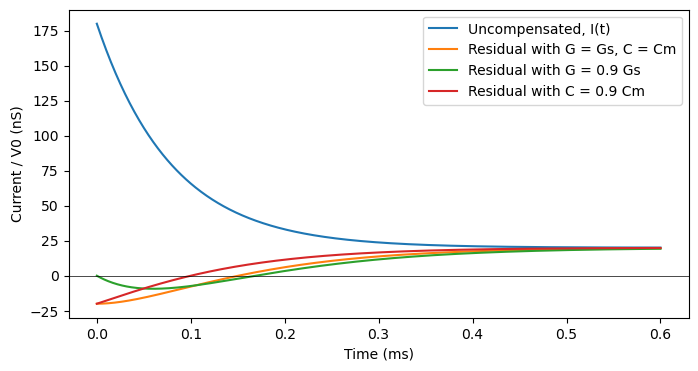

In [2]:
def residual(t, Gs, Cm, Gm, G, C):
    """ Residual current divided by V0 (nS), for a cell (Gs, Cm, Gm) and C-slow settings (G, C). """
    tau, Ginf = Cm / (Gs + Gm), Gs * Gm / (Gs + Gm)
    return Gs * np.exp(-t / tau) + Ginf * (0.5 - np.exp(-t / tau)) - G * np.exp(-t / (C / G))


Gs, Cm, Gm = 1 / 5e-3, 20, 50   # Rs = 5 MOhm, Cm = 20 pF, Gm = 50 nS
t = np.linspace(0, 0.6, 601)
fig, ax = plt.subplots(figsize=(8, 4))
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Current / V0 (nS)')
ax.plot(t, residual(t, Gs, Cm, Gm, 1e-9, 1e-9), label='Uncompensated, I(t)')
ax.plot(t, residual(t, Gs, Cm, Gm, Gs, Cm), label='Residual with G = Gs, C = Cm')
ax.plot(t, residual(t, Gs, Cm, Gm, 0.9 * Gs, Cm), label='Residual with G = 0.9 Gs')
ax.plot(t, residual(t, Gs, Cm, Gm, Gs, 0.9 * Cm), label='Residual with C = 0.9 Cm')
ax.axhline(0, color='k', lw=0.5)
ax.legend()
plt.show()

## Three integrals of the residual

If $G_\infty$ is small compared to $G_s$ ("usually about 2 orders of magnitude smaller", Sigworth 1995c), the residual is approximately

\begin{align}
\frac{\Delta I(t)}{V_0} \approx
    \frac{t}{\tau'^2} e^{-t/\tau'} \Delta C
    + \left(1 - \frac{t}{\tau'}\right) e^{-t/\tau'} \Delta G
    + G_\infty \left[\frac{1}{2} - \left(1 + \frac{t}{\tau'}\right) e^{-t/\tau'} \right]
\end{align}

An imbalance in $C$ gives a monophasic contribution, an imbalance in $G$ a biphasic one with a zero crossing at $t = \tau'$, and $G_\infty$ adds a "pedestal".
To separate the three, the procedure computes three integrals of the residual: a "long integral" $J_L$, a "short integral" $J_S$ and a pedestal $P$.
Sigworth 1995c gives their expected values (Eqs. 8-10)

\begin{align}
J_L &= \frac{1}{V_0}\int_0^{4\tau'} \Delta I\, dt = 0.908 \Delta C + \tau' (0.073 \Delta G + 0.11 G_\infty) \\
J_S &= \frac{1}{V_0}\left(\int_0^{\tau'} \Delta I\, dt - \int_{\tau'}^{2\tau'} \Delta I\, dt\right) = -0.066 \Delta C + \tau' (0.465 \Delta G - 0.334 G_\infty) \\
P   &= \frac{1}{V_0}\int_{2\tau'}^{4\tau'} \Delta I\, dt = 0.314 \Delta C + \tau' (-0.197 \Delta G + 0.569 G_\infty)
\end{align}


In [3]:
terms = {
    'dC': lambda t: t * np.exp(-t),
    'dG': lambda t: (1 - t) * np.exp(-t),
    'Ginf': lambda t: 0.5 - (1 + t) * np.exp(-t),
}
windows = {
    'J_L': lambda f: quad(f, 0, 4)[0],
    'J_S': lambda f: quad(f, 0, 1)[0] - quad(f, 1, 2)[0],
    'P': lambda f: quad(f, 2, 4)[0],
}
for name, integral in windows.items():
    print(f'{name:>3}: ' + '  '.join(f'{k} {integral(f):+.3f}' for k, f in terms.items()))

J_L: dC +0.908  dG +0.073  Ginf +0.110
J_S: dC -0.066  dG +0.465  Ginf -0.334
  P: dC +0.314  dG -0.197  Ginf +0.569


In [4]:
def integrals(Gs, Cm, Gm, G, C):
    """ Returns (J_L, J_S, P) for a cell (Gs, Cm, Gm) and C-slow settings (G, C), all divided by V0. """
    tau, Ginf, tp = Cm / (Gs + Gm), Gs * Gm / (Gs + Gm), C / G

    def integral(a, b):
        # Integral of the residual from a * tau' to b * tau'
        a, b = a * tp, b * tp
        exp_int = lambda T: T * (np.exp(-a / T) - np.exp(-b / T))  # noqa
        return Gs * exp_int(tau) + Ginf * (0.5 * (b - a) - exp_int(tau)) - G * exp_int(tp)

    return integral(0, 4), integral(0, 1) - integral(1, 2), integral(2, 4)

## The iterative procedure

Inverting Eqs. 8-10 gives the corrections (Sigworth 1995c, Eqs. 11-13)

\begin{align}
\Delta C &= 1.235 J_L - 0.393 J_S - 0.47 P \\
\Delta G &= (-0.418 J_L + 2.995 J_S + 1.839 P) / \tau' \\
G_\infty &= (-0.826 J_L + 1.254 J_S + 2.653 P) / \tau'
\end{align}

and the membrane conductance can then be estimated as $G_m = G G_\infty / (G - G_\infty)$.

The corrections are applied to the C-slow settings, a new square wave is applied, and the procedure is repeated "until the corrections become smaller than a convergence criterion value".

In [5]:
def corrections(Gs, Cm, Gm, G, C):
    """ Returns the corrections (dC, dG) and the estimate of Gm, for a cell (Gs, Cm, Gm) and settings (G, C). """
    JL, JS, P = integrals(Gs, Cm, Gm, G, C)
    tp = C / G
    dC = 1.235 * JL - 0.393 * JS - 0.47 * P
    dG = (-0.418 * JL + 2.995 * JS + 1.839 * P) / tp
    Ginf = (-0.826 * JL + 1.254 * JS + 2.653 * P) / tp
    return dC, dG, G * Ginf / (G - Ginf)


def auto_cslow(Gs, Cm, Gm, G, C, max_iter=100, tol=1e-9, verbose=False):
    """
    Iterates the C-slow settings (G, C) for a cell (Gs, Cm, Gm), starting from an initial guess.

    Returns the final settings (G, C), the final estimate of Gm, and a boolean indicating convergence.
    """
    for i in range(max_iter):
        dC, dG, Gm_est = corrections(Gs, Cm, Gm, G, C)
        C, G = C + dC, G + dG
        if verbose:
            print(f'{i:>3}: Rs {1e3 / G:8.4f} MOhm, C {C:8.4f} pF, Gm {Gm_est:8.3f} nS')
        if not (0 < C < 100 * Cm and 0 < G < 100 * Gs):
            return G, C, Gm_est, False
        if abs(dC) < tol * Cm and abs(dG) < tol * Gs:
            return G, C, Gm_est, True
    return G, C, Gm_est, False

With a small membrane conductance, starting from settings that are 20% off, the procedure converges to the true values:

In [6]:
Gs, Cm, Gm = 1 / 5e-3, 20, 2   # Rs = 5 MOhm, Cm = 20 pF, Gm = 2 nS (Rs * Gm = 0.01)
G, C, Gm_est, ok = auto_cslow(Gs, Cm, Gm, 0.8 * Gs, 1.2 * Cm, verbose=True)
print(f'Converged: {ok}')

  0: Rs   5.0875 MOhm, C  19.6287 pF, Gm   10.531 nS
  1: Rs   4.9999 MOhm, C  20.0012 pF, Gm    2.005 nS
  2: Rs   5.0000 MOhm, C  20.0015 pF, Gm    2.004 nS
  3: Rs   5.0000 MOhm, C  20.0016 pF, Gm    2.004 nS
  4: Rs   5.0000 MOhm, C  20.0016 pF, Gm    2.004 nS
  5: Rs   5.0000 MOhm, C  20.0016 pF, Gm    2.004 nS
Converged: True


## Larger membrane conductances

The expressions for the corrections were derived assuming $G_\infty \ll G_s$, or equivalently $R_s G_m \ll 1$.
In whole-cell recordings with a large conductance at the holding potential (e.g. a large inward rectifier current at a holding potential near $E_K$), this estimate is imprecise.

In [7]:
def fixed_point(Gs, Cm, Gm):
    """ Returns the settings (G, C) at which the corrections vanish, for a cell (Gs, Cm, Gm). """
    def f(z):
        dC, dG, _ = corrections(Gs, Cm, Gm, np.exp(z[0]) * Gs, np.exp(z[1]) * Cm)
        return [dG / Gs, dC / Cm]
    z = fsolve(f, [0, 0], xtol=1e-12)
    return np.exp(z[0]) * Gs, np.exp(z[1]) * Cm


print('Rs*Gm  R-series/Rs  C-slow/Cm  Gm-estimate/Gm  Converges')
for k in [0.01, 0.03, 0.1, 0.2, 0.3, 0.35, 0.4, 0.45, 0.5]:
    G, C = fixed_point(1, 1, k)
    _, _, Gm_est, ok = auto_cslow(1, 1, k, 1.05 * G, 0.95 * C, max_iter=300)
    print(f'{k:5.2f}  {1 / G:11.3f}  {C:9.3f}  {Gm_est / k:14.3f}  {ok}')

Rs*Gm  R-series/Rs  C-slow/Cm  Gm-estimate/Gm  Converges
 0.01        1.000      1.000           1.002  True
 0.03        1.000      1.001           1.009  True
 0.10        1.000      1.008           1.035  True
 0.20        1.002      1.034           1.080  True
 0.30        1.008      1.083           1.138  True
 0.35        1.014      1.121           1.175  True
 0.40        1.024      1.177           1.223  True
 0.45        1.045      1.269           1.292  True
 0.50        1.103      1.496          22.656  False


/tmp/ipykernel_2401162/531477106.py:6: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  z = fsolve(f, [0, 0], xtol=1e-12)


/tmp/ipykernel_2401162/531477106.py:6: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  z = fsolve(f, [0, 0], xtol=1e-12)


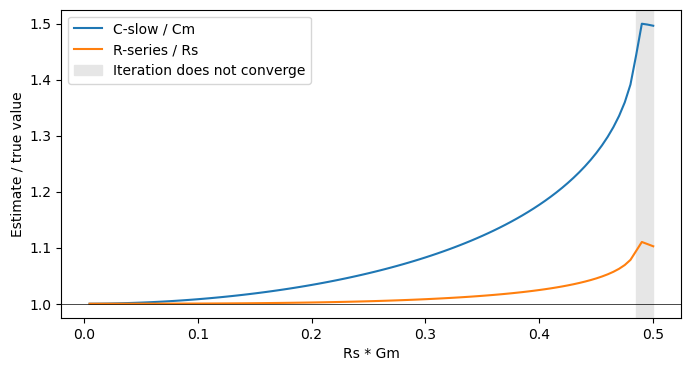

In [8]:
k = np.linspace(0.005, 0.5, 100)
fp = np.array([fixed_point(1, 1, x) for x in k])
ok = np.array([auto_cslow(1, 1, x, 1.05 * g, 0.95 * c, max_iter=300)[3] for x, (g, c) in zip(k, fp)])

fig, ax = plt.subplots(figsize=(8, 4))
ax.set_xlabel('Rs * Gm')
ax.set_ylabel('Estimate / true value')
ax.plot(k, fp[:, 1], label='C-slow / Cm')
ax.plot(k, 1 / fp[:, 0], label='R-series / Rs')
if not ok.all():
    ax.axvspan(k[~ok].min(), k.max(), color='0.9', label='Iteration does not converge')
ax.axhline(1, color='k', lw=0.5)
ax.legend()
plt.show()

As $R_s G_m$ increases, the procedure increasingly **over**estimates $C_m$, while the estimate of $R_s$ remains within 10% of the true value.
At $R_s G_m \approx 0.5$ the plain iteration no longer converges.
According to the EPC-10 manual, if the procedure does not converge within the timeout period, the C-slow and R-series settings remain unchanged.

## Inferring the true values from the amplifier's estimates

If $G_m$ is known (or estimated separately), the reported settings can be inverted to find the cell parameters that would have produced them:

In [ ]:
def invert(Rs_reported, C_reported, Gm, n_iter=100, tol=1e-10):
    """
    Returns the (Rs, Cm) that the procedure would report as (Rs_reported, C_reported), for a cell with
    membrane conductance Gm. Rs in GOhm, C in pF, Gm in nS.
    """
    Rs, Cm = Rs_reported, C_reported
    for i in range(n_iter):
        G, C = fixed_point(1 / Rs, Cm, Gm)
        Rs, Cm = Rs * Rs_reported * G, Cm * C_reported / C
        if abs(Rs_reported * G - 1) < tol and abs(C_reported / C - 1) < tol:
            return Rs, Cm
    raise RuntimeError('Inversion did not converge')


Rs_reported, C_reported = 5e-3, 20
for Gm in [10, 40, 80]:
    Rs, Cm = invert(Rs_reported, C_reported, Gm)
    print(f'Gm {Gm:>3} nS: reported Rs {1e3 * Rs_reported:.2f} MOhm, C-slow {C_reported:.1f} pF -> '
          f'true Rs {1e3 * Rs:.2f} MOhm, Cm {Cm:.2f} pF (Rs * Gm = {Rs * Gm:.2f})')

## Conclusion

We have reimplemented the automatic C-slow procedure described by Sigworth 1995c, using integration windows reconstructed from the published coefficients.
For cells with a small membrane conductance ($R_s G_m < 0.1$) it estimates $R_s$ and $C_m$ accurately.
For larger membrane conductances it overestimates $C_m$ (by about 8% at $R_s G_m = 0.3$ and 50% at $R_s G_m = 0.5$), while the estimate of $R_s$ stays within a few percent and the estimate of $G_m$ (Eq. 13) is also too high; above $R_s G_m \approx 0.5$ the iteration does not converge.

Several aspects of the real implementation are not included here:
- Stimulus and current filters, and the empirically determined delay added before each integration window (Sigworth 1995c, section 3.2).
- Fast capacitance, which is assumed to be perfectly compensated.
- Time-dependence or non-linearity of the membrane conductance: $G_m$ is assumed constant over the $\pm 5$ mV square wave.
- The initialisation routine used when corrections are excessive.